# SCENIC+ links: search space, region-to-gene and TF-to-gene

SCENIC+ builds enhancer-driven gene regulatory networks (eRegulons) from paired scRNA +
scATAC data. This tutorial covers the three link tables it combines into eRegulons:

1. the **search space**: which regions may regulate which gene (gene body ± 150 kb);
2. **region-to-gene** links: how well the accessibility of each region in a gene's search
   space predicts that gene's expression (gradient boosting / random forest importance,
   signed by Spearman correlation);
3. **TF-to-gene** links: GRNBoost2 regressions of every gene on the expression of the
   transcription factors, signed by Pearson correlation.

`epione.scenic` reimplements these steps without scenicplus, arboreto, dask or ray, with two
backends for the tree models:

* `method="fast"` (default): histogram trees. Predictors are binned once (one bin per
  distinct value, so no split candidate is lost) and shared by all genes, sparse
  expression is read through its non-zeros, and all genes are fitted in one parallel loop.
* `method="exact"`: a numba port of the scikit-learn 1.3.2 code path SCENIC+ was built on;
  the importances are **bit-identical** to scenicplus 1.0 whatever scikit-learn is
  installed. Use it to reproduce a scenicplus run.

Both are compared with scenicplus at the end of the tutorial.

Data: the 10x multiome human cerebellum 3k dataset of the official SCENIC+ tutorial, with
the authors' cell annotation. Everything is downloaded with `pooch` and processed with
Epione.

In [1]:
import os
import tarfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc

import epione as epi
import epione.scenic as scenic

DATA = Path(os.environ.get("EPIONE_SCENIC_TUTORIAL_DATA", "data_scenic_cerebellum"))
DATA.mkdir(parents=True, exist_ok=True)
N_JOBS = int(os.environ.get("EPIONE_N_JOBS", "8"))

TENX = "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/human_brain_3k/"
FILES = {
    "human_brain_3k_filtered_feature_bc_matrix.tar.gz": (TENX + "human_brain_3k_filtered_feature_bc_matrix.tar.gz",
        "81a386c1f733e48d8fa6026e334e288333b2ad5586f9d4088bfe8b7528996fd4"),
    "human_brain_3k_atac_fragments.tsv.gz": (TENX + "human_brain_3k_atac_fragments.tsv.gz",
        "dd3513999f458e97fdf635cc0641df337c734119b122074da9dcfda17af17226"),
    "human_brain_3k_atac_fragments.tsv.gz.tbi": (TENX + "human_brain_3k_atac_fragments.tsv.gz.tbi",
        "7d89aae2ebef104d8491bedf5cccdbe3fe69d53a142071019a7ed2739b85fdd6"),
    "human_brain_3k_atac_peaks.bed": (TENX + "human_brain_3k_atac_peaks.bed",
        "b92d45dccbf2c49b7cdec8e9a2f0fd755d7b3a712de7c778dddf9a29cdb66f8f"),
    "cell_data_human_cerebellum.tsv": (
        "https://raw.githubusercontent.com/aertslab/pycisTopic/polars/data/cell_data_human_cerebellum.tsv",
        "e762f44f1a6523614c019419bf8971da536bba72ca5a0322d0e1b215f863a56c"),
    "Homo_sapiens.GRCh38.113.gtf.gz": (
        "https://ftp.ensembl.org/pub/release-113/gtf/homo_sapiens/Homo_sapiens.GRCh38.113.gtf.gz",
        "62f1709b40e083ce9d4cdc64a86b5ffec2c5d5371434bb7095c74dc89079c466"),
    "hg38.chrom.sizes": ("https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes",
        "e1d9152418038457a959e949d99c9caf7ae3e4f87cfbb4ffe7d8b9a54ba1202b"),
    "motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl": (
        "https://resources.aertslab.org/cistarget/motif2tf/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl",
        "81eb754118e27e854974301b1400fcf519489f8be5249239671fb288cb501c31"),
}
paths = {name: Path(os.path.relpath(pooch.retrieve(url, known_hash=f"sha256:{h}", fname=name, path=DATA,
                                                   progressbar=False)))
         for name, (url, h) in FILES.items()}
{k: f"{v.stat().st_size / 1e6:,.1f} MB" for k, v in paths.items()}

{'human_brain_3k_filtered_feature_bc_matrix.tar.gz': '170.1 MB',
 'human_brain_3k_atac_fragments.tsv.gz': '1,647.7 MB',
 'human_brain_3k_atac_fragments.tsv.gz.tbi': '0.9 MB',
 'human_brain_3k_atac_peaks.bed': '3.2 MB',
 'cell_data_human_cerebellum.tsv': '0.3 MB',
 'Homo_sapiens.GRCh38.113.gtf.gz': '64.1 MB',
 'hg38.chrom.sizes': '0.0 MB',
 'motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl': '98.7 MB'}

## Expression and cell annotation

Raw counts of the annotated multiome cells. SCENIC+ fits its models on raw counts.

In [2]:
mtx_dir = DATA / "filtered_feature_bc_matrix"
if not mtx_dir.exists():
    with tarfile.open(paths["human_brain_3k_filtered_feature_bc_matrix.tar.gz"]) as tf:
        tf.extractall(DATA)
rna = sc.read_10x_mtx(mtx_dir, var_names="gene_symbols")
rna.var_names_make_unique()
cell_data = pd.read_table(paths["cell_data_human_cerebellum.tsv"], index_col=0)
cell_data.index = cell_data.index.str.replace("-10x_multiome_brain", "", regex=False)
rna = rna[rna.obs_names.isin(cell_data.index)].copy()
rna.obs = cell_data.loc[rna.obs_names, ["VSN_cell_type", "Seurat_cell_type"]]
rna

AnnData object with n_obs × n_vars = 2313 × 36601
    obs: 'VSN_cell_type', 'Seurat_cell_type'
    var: 'gene_ids', 'feature_types'

In [3]:
rna.obs["Seurat_cell_type"].value_counts()

Seurat_cell_type
MOL          813
BG           314
NFOL         305
OPC          183
GC           125
INH_VIP      111
MGL           74
COP           72
MG            68
INH_SST       66
GP            43
INH_SNCG      43
AST           37
PURK          28
ENDO          16
INH_PVALB     15
Name: count, dtype: int64

## Accessibility with Epione

Fragments of the same cells are counted in the 10x peak set, reduced with ArchR-style
iterative LSI and smoothed with MAGIC (`epi.tl.add_impute_weights` / `impute_matrix`).
The smoothed matrix plays the role of the topic-imputed accessibility SCENIC+ uses for
region-to-gene regression.

In [4]:
chrom_sizes = pd.read_table(paths["hg38.chrom.sizes"], header=None, names=["chrom", "size"])
chrom_sizes = dict(chrom_sizes[chrom_sizes.chrom.str.fullmatch(r"chr[0-9XY]+")].values)
t0 = time.time()
atac = epi.pp.import_fragments(str(paths["human_brain_3k_atac_fragments.tsv.gz"]), chrom_sizes,
                               whitelist=list(rna.obs_names), min_num_fragments=0, n_jobs=N_JOBS)
peaks = pd.read_table(paths["human_brain_3k_atac_peaks.bed"], comment="#", header=None,
                      names=["chrom", "start", "end"])
peaks = peaks[peaks.chrom.isin(chrom_sizes)]
pm = epi.pp.make_peak_matrix(atac, [f"{c}:{s}-{e}" for c, s, e in peaks.values])
pm = pm[rna.obs_names].copy()
print(f"{pm.n_obs} cells x {pm.n_vars} peaks in {time.time() - t0:.0f} s")

└─ scanning data_scenic_cerebellum/human_brain_3k_atac_fragments.tsv.gz


  └─ imported 2,313 cells  (75,353,510 unique fragments)


└─ building peak matrix: 2,313 cells × 133,986 peaks


  └─ peak matrix nnz=21,294,120
2313 cells x 133986 peaks in 311 s


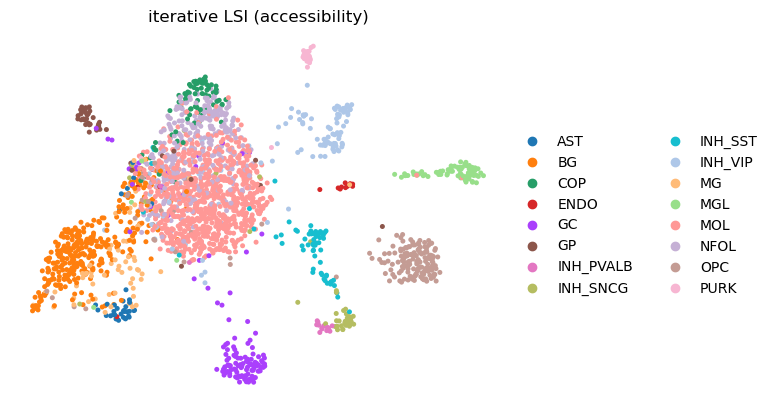

In [5]:
epi.tl.iterative_lsi(pm, n_components=30, iterations=2, var_features=50000, seed=0, verbose=False)
epi.tl.add_impute_weights(pm, use_rep="X_iterative_lsi", verbose=False)
pm.obs["Seurat_cell_type"] = rna.obs["Seurat_cell_type"].values
sc.pp.neighbors(pm, use_rep="X_iterative_lsi")
sc.tl.umap(pm)
sc.pl.umap(pm, color="Seurat_cell_type", frameon=False, title="iterative LSI (accessibility)")

## Search space

Gene coordinates come from the Ensembl 113 GTF (protein-coding transcripts; the columns of
the biomart query scenicplus uses). Every peak overlapping a gene body extended by 150 kb
on both sides is paired with the gene; `Distance` is the signed distance from the peak
midpoint to the gene body (0 inside the gene, negative upstream).

In [6]:
annot = scenic.gene_annotation_from_gtf(paths["Homo_sapiens.GRCh38.113.gtf.gz"])
t0 = time.time()
search_space = scenic.get_search_space(pm.var_names, rna.var_names, annot,
                                       upstream=(1000, 150000), downstream=(1000, 150000))
print(f"{len(search_space):,} region-gene pairs for {search_space.Gene.nunique():,} genes "
      f"in {time.time() - t0:.1f} s")
search_space.head()

466,263 region-gene pairs for 18,525 genes in 5.9 s


,Name,Gene,Distance
0,chr1:12591015-12591824,AADACL3,[124690]
1,chr1:12595032-12595653,AADACL3,[120768]
2,chr1:12595766-12596416,AADACL3,[120019]
3,chr1:12608987-12609866,AADACL3,[106684]
4,chr1:12614735-12615670,AADACL3,[100908]


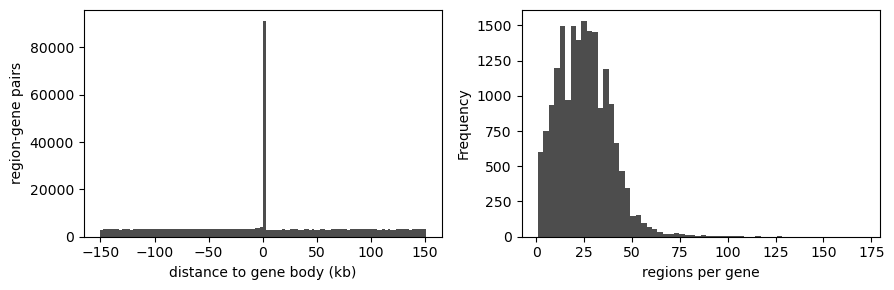

In [7]:
d = search_space.Distance.str.strip("[]").astype(int)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(d / 1e3, bins=120, color="0.3")
ax[0].set_xlabel("distance to gene body (kb)")
ax[0].set_ylabel("region-gene pairs")
search_space.Gene.value_counts().plot.hist(bins=60, ax=ax[1], color="0.3")
ax[1].set_xlabel("regions per gene")
plt.tight_layout()

## Genes to model

The full SCENIC+ run regresses every gene; here we use the 1,500 most variable genes (plus
the TFs among them) to keep the tutorial short. The functions take `targets=` for that.

In [8]:
norm = rna.copy()
sc.pp.normalize_total(norm, target_sum=1e4)
sc.pp.log1p(norm)
sc.pp.highly_variable_genes(norm, n_top_genes=1500, flavor="seurat")
motif2tf = pd.read_table(paths["motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl"], low_memory=False)
tf_names = sorted(set(motif2tf["gene_name"].dropna()) & set(rna.var_names))
targets = [g for g in rna.var_names[norm.var.highly_variable] if g in set(search_space.Gene)]
print(len(tf_names), "TFs with a motif annotation;", len(targets), "target genes")

1597 TFs with a motif annotation; 1026 target genes


## Region-to-gene links

For each gene, a gradient-boosting model predicts expression from the smoothed accessibility
of its search-space regions (scenicplus: 500 trees at learning rate 0.01, `max_features=0.1`,
seed 666; the fast backend takes the same shrinkage budget in 250 steps of 0.02). `importance` is the feature importance (sums to 1 per gene) and `rho` the Spearman
correlation, used later to split activating and repressing links.

In [9]:
acc_regions = search_space.loc[search_space.Gene.isin(targets), "Name"].unique()
acc = epi.tl.impute_matrix(pm, list(acc_regions)).astype(np.float32)
t0 = time.time()
r2g = scenic.region_to_gene(rna, acc, search_space, importance="GBM", correlation="SR",
                            targets=targets, n_jobs=N_JOBS, accessibility_var_names=acc_regions)
print(f"{len(r2g):,} region-gene links for {r2g.target.nunique():,} genes in {time.time() - t0:.0f} s")
r2g.sort_values("importance_x_abs_rho", ascending=False).head(10)

26,436 region-gene links for 1,026 genes in 6 s


,target,region,importance,rho,importance_x_rho,importance_x_abs_rho,Distance
21819,SLC22A10,chr11:63445198-63445943,1.000000,0.329887,0.329887,0.329887,[-133787]
26359,ZNF804A,chr2:184837546-184838418,0.263477,0.581379,0.153180,0.153180,[0]
6187,CST3,chr20:23655386-23656307,0.222261,0.615225,0.136740,0.136740,[17373]
4214,CDH6,chr5:31213394-31214217,0.581079,0.222688,0.129399,0.129399,[0]
9071,GAD2,chr10:26221316-26222208,0.297580,0.416989,0.124088,0.124088,[0]
13952,LILRB4,chr19:54523082-54523965,1.000000,0.123420,0.123420,0.123420,[120365]
11262,HTR2C,chrX:114584224-114585074,1.000000,0.115264,0.115264,0.115264,[0]
24110,TENM1,chrX:124388279-124389087,0.303468,0.377291,0.114496,0.114496,[0]
18843,PRR16,chr5:120405244-120406036,0.257784,0.437139,0.112687,0.112687,[58660]
14482,LUZP2,chr11:24497907-24498598,0.224908,0.497620,0.111919,0.111919,[0]


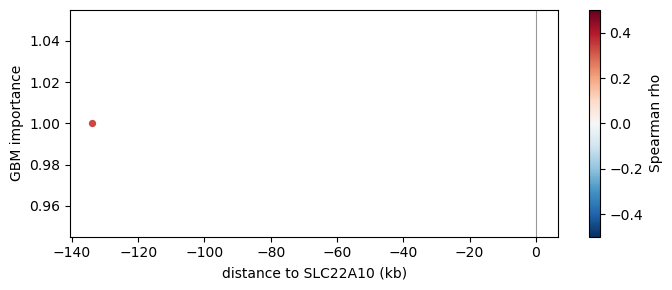

In [10]:
gene = r2g.groupby("target").importance_x_abs_rho.max().idxmax()
g = r2g[r2g.target == gene].copy()
g["kb"] = g.Distance.str.strip("[]").astype(int) / 1e3
fig, ax = plt.subplots(figsize=(7, 3))
sca = ax.scatter(g.kb, g.importance, c=g.rho, cmap="RdBu_r", vmin=-0.5, vmax=0.5, s=18)
ax.axvline(0, color="0.6", lw=0.8)
ax.set_xlabel(f"distance to {gene} (kb)")
ax.set_ylabel("GBM importance")
plt.colorbar(sca, label="Spearman rho")
plt.tight_layout()

Random forests (`max_features="sqrt"`; 1000 trees in scenicplus and `method="exact"`, 100
in the fast backend) are the other importance model SCENIC+ offers; here on 60 genes.

In [11]:
t0 = time.time()
r2g_rf = scenic.region_to_gene(rna, acc, search_space, importance="RF", targets=targets[:60],
                               n_jobs=N_JOBS, accessibility_var_names=acc_regions)
both = r2g_rf.merge(r2g, on=["target", "region"], suffixes=("_rf", "_gbm"))
print(f"RF: {r2g_rf.target.nunique()} genes in {time.time() - t0:.0f} s; "
      f"Spearman(RF, GBM importance) = {both.importance_rf.corr(both.importance_gbm, method='spearman'):.2f}")

RF: 60 genes in 5 s; Spearman(RF, GBM importance) = 0.80


## TF-to-gene links (GRNBoost2)

Each target is regressed on the expression of all TFs with stochastic gradient boosting
(up to 5000 trees, `subsample=0.9`, out-of-bag early stopping; the same settings in both
backends); importances are multiplied by the number of trees, as arboreto does. Genes without expression are skipped exactly (their
importances are zero), which upstream spends 5000 trees on.

In [12]:
t0 = time.time()
tf2g = scenic.tf_to_gene(rna, tf_names, targets=targets, n_jobs=N_JOBS)
print(f"{len(tf2g):,} TF-gene links in {time.time() - t0:.0f} s")
tf2g.head()

88,316 TF-gene links in 3 s


,TF,target,importance,regulation,rho
0,ABL1,DLGAP2,0.034240,1,0.189689
1,ABL1,NAMPT,0.036390,1,0.131596
2,ABL1,PLCH1,0.004999,1,0.033440
3,ABL1,DOCK2,0.070986,0,0.027607
4,ABL1,LAMA4,1.700472,1,0.363632


In [13]:
top = (tf2g[(tf2g.TF != tf2g.target) & (tf2g.regulation == 1)]
       .sort_values("importance", ascending=False).groupby("target").head(3))
markers = [m for m in ["GABRA6", "PAX6", "CBLN3", "MBP", "PLP1", "GFAP", "AQP4", "CSF1R", "PDGFRA"]
           if m in set(top.target)]
top[top.target.isin(markers)].sort_values(["target", "importance"], ascending=[True, False])

,TF,target,importance,regulation,rho
18409,GLI3,AQP4,2.526497,1,0.651277
35756,NFIA,AQP4,2.383178,1,0.385329
48335,RFX4,AQP4,2.286389,1,0.342250
57706,TAL1,CSF1R,3.001321,1,0.518000
23646,IKZF1,CSF1R,2.955784,1,0.357249
35034,NFATC2,CSF1R,1.713155,1,0.527698
48401,RFX4,GFAP,4.103021,1,0.336271
32525,MXD1,GFAP,1.842600,1,0.294023
18487,GLI3,GFAP,1.712805,1,0.338542
54866,SOX6,PDGFRA,3.740378,1,0.522732


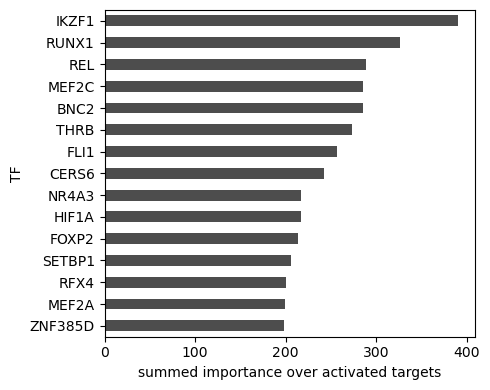

In [14]:
reg = (tf2g[(tf2g.TF != tf2g.target) & (tf2g.regulation == 1)]
       .groupby("TF").importance.sum().sort_values(ascending=False).head(15))
ax = reg[::-1].plot.barh(figsize=(5, 4), color="0.3")
ax.set_xlabel("summed importance over activated targets")
plt.tight_layout()

## Fast vs exact backend

The same 60 genes with both backends, plus the exact backend with another seed. GRNBoost2
stops most genes after 25–55 trees, each node drawing 10 % of the TFs at random. So which
TFs receive importance is largely random: two exact runs that differ only in the seed
share about a quarter of their top-50 TFs. The fast backend should agree with the exact one
about as well as the exact one agrees with itself. Region-to-gene links are much more
stable.

In [15]:
from scipy.stats import spearmanr


def agreement(a, b, key, k):
    """Median per-gene Spearman (union of links) and top-k overlap (Jaccard) of two tables."""
    rho, jac = [], []
    for t, ga in a.groupby("target"):
        gb = b[b.target == t]
        u = sorted(set(ga[key]) | set(gb[key]))
        if len(u) < 3:
            continue
        va = ga.set_index(key).importance.reindex(u).fillna(0)
        vb = gb.set_index(key).importance.reindex(u).fillna(0)
        rho.append(spearmanr(va, vb)[0])
        ta, tb = set(ga.nlargest(k, "importance")[key]), set(gb.nlargest(k, "importance")[key])
        jac.append(len(ta & tb) / len(ta | tb))
    return np.nanmedian(rho), np.median(jac)


genes60 = targets[:60]
runs, rows = {}, []
for name, fn in [
    ("TF2G exact", lambda: scenic.tf_to_gene(rna, tf_names, method="exact", targets=genes60, n_jobs=N_JOBS)),
    ("TF2G exact, seed 667", lambda: scenic.tf_to_gene(rna, tf_names, method="exact", seed=667,
                                                       targets=genes60, n_jobs=N_JOBS)),
    ("TF2G fast", lambda: scenic.tf_to_gene(rna, tf_names, method="fast", targets=genes60, n_jobs=N_JOBS)),
    ("R2G exact", lambda: scenic.region_to_gene(rna, acc, search_space, method="exact", targets=genes60,
                                                n_jobs=N_JOBS, accessibility_var_names=acc_regions)),
    ("R2G exact, seed 667", lambda: scenic.region_to_gene(rna, acc, search_space, method="exact", seed=667,
                                                          targets=genes60, n_jobs=N_JOBS,
                                                          accessibility_var_names=acc_regions)),
    ("R2G fast", lambda: scenic.region_to_gene(rna, acc, search_space, method="fast", targets=genes60,
                                               n_jobs=N_JOBS, accessibility_var_names=acc_regions)),
    ("R2G corr", lambda: scenic.region_to_gene(rna, acc, search_space, method="corr", targets=genes60,
                                               n_jobs=N_JOBS, accessibility_var_names=acc_regions)),
]:
    t0 = time.time()
    out = fn()
    runs[name] = out[out.TF != out.target] if "TF" in out else out
    rows.append((name, time.time() - t0))
table = []
for name, sec in rows:
    ref = "TF2G exact" if name.startswith("TF2G") else "R2G exact"
    key, k = ("TF", 50) if name.startswith("TF2G") else ("region", 10)
    r, j = (1.0, 1.0) if name == ref else agreement(runs[name], runs[ref], key, k)
    table.append({"run": name, "seconds": round(sec, 1), "median Spearman vs exact": round(r, 2),
                  f"median top-k Jaccard vs exact": round(j, 2), "k": k})
pd.DataFrame(table).set_index("run")

,seconds,median Spearman vs exact,median top-k Jaccard vs exact,k
run,,,,
TF2G exact,1.1,1.00,1.00,50
"TF2G exact, seed 667",1.0,-0.04,0.30,50
TF2G fast,0.3,-0.05,0.31,50
R2G exact,5.3,1.00,1.00,10
"R2G exact, seed 667",5.3,0.77,0.67,10
R2G fast,1.3,0.69,0.54,10
R2G corr,0.9,0.23,0.33,10


On these 60 genes, fast TF-to-gene links match the exact ones as closely as a reseeded exact
run does: the top-50 TFs share about 30 % in both comparisons. Region-to-gene links are far
more reproducible, but here the fast backend is somewhat less consistent with the exact one
(Spearman 0.69, top-10 Jaccard 0.54) than a reseeded exact run is (0.77, 0.67). On the full
reference data, with topic-imputed accessibility, the fast backend matched the reseeded
exact run in top-10 overlap (0.67 vs 0.67), and its Spearman was slightly lower (0.89 vs 0.92).
Use `method="exact"` when region-to-gene links should reproduce a scenicplus run.

## Parity with scenicplus 1.0

### `method="exact"`

Reference: scenicplus 1.0a2 / arboreto 0.1.6 / scikit-learn 1.3.2 on the same dataset
(2,313 multiome cells; topic-imputed accessibility; all 36,601 genes; seed 666), generated
outside this repository. Gates are pre-registered in
`tests/parity/scenic_links/MANIFEST.md`.

| Output | Rows | Result |
|---|---|---|
| Search space | 1,573,743 | byte-identical, same order (224 s → 17 s) |
| TF-to-gene `importance` (GRNBoost2) | 2,597,463 | identical links, **100 % bit-identical**, same row order |
| TF-to-gene `rho` / `regulation` | 2,597,463 | max abs err 5.5e-14 / 0 mismatches |
| Region-to-gene GBM `importance` | 1,573,743 | **100 % bit-identical**, same order |
| Region-to-gene RF `importance` | 1,573,743 | **100 % bit-identical**, same order |
| Region-to-gene `rho` (Spearman) | 1,573,743 | max abs err 4.4e-16, NaN positions identical |
| `n_jobs=1` vs `n_jobs=6` | — | identical |

Single-core speed against scikit-learn 1.3.2 + arboreto on the same inputs: GRNBoost2
1.06× per expressed gene (unexpressed genes are skipped exactly, ~40 % of the reference CPU
time), region-to-gene GBM 1.3×, RF 1.55×, search space 13×.

### `method="fast"`

Same reference, full data, gates pre-registered in the same MANIFEST. Each gate is the fixed
threshold or the exact backend's own seed-to-seed spread, whichever is lower (seed 667 vs
the reference's 666).

| Gate | fast | exact, other seed | Result |
|---|---|---|---|
| TF2G median per-gene Spearman | −0.10 | −0.11 | pass |
| TF2G median top-50 TF Jaccard | 0.28 | 0.27 | pass |
| R2G median per-gene Spearman | 0.89 | 0.92 | pass (≥ 0.8) |
| R2G median top-10 region Jaccard | 0.67 | 0.67 | pass |
| eGRN TF-set Jaccard, direct / extended | 0.40 / 0.50 | 0.41 / 0.46 | **fail** (direct, by about one TF) / pass |
| eGRN target-gene Jaccard, direct / extended | 0.45 / 0.45 | 0.42 / 0.43 | pass |
| `n_jobs=1` vs `n_jobs=8` | identical | | pass |

The fast links agree with scenicplus about as well as scenicplus agrees with itself under
another seed. That spread is large: eRegulons from two exact runs share less than half of
their TFs and target genes, so treat individual eRegulons as one sample of a noisy procedure.

Wall time on the full data (8 threads):

| Step | exact | fast | speedup |
|---|---|---|---|
| TF-to-gene (36,601 targets) | 1,758 s | 234 s | 7.5× |
| Region-to-gene GBM (1.57 M pairs) | 1,119 s | 212 s | 5.3× |
| Region-to-gene `method="corr"` | | 38 s | 29× |
